# Explainable and Drift-Aware Predictive Maintenance for IoT-Monitored Industrial Equipment
**Dataset:** NASA C-MAPSS, a public benchmark of simulated turbofan engines run until failure. Each engine has 21 sensors recorded every operating cycle.

**Why this dataset:** public transformer data with real failures does not exist, and C-MAPSS is the standard benchmark for predictive maintenance. The method (sensor features, early-warning model, explanations, drift checks) applies to any sensor-monitored asset, including smart grid equipment.

**Questions**
1. Can we warn that an engine will fail within **30 cycles**, better than a simple rule or age-based maintenance?
2. Which sensors drive each alert (explainability)?
3. What happens when operating conditions change (drift), and how do we respond?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from scipy.stats import ks_2samp
from xgboost import XGBClassifier
import shap
warnings.filterwarnings("ignore")
FIG = "../figures" if os.path.isdir("../figures") else "figures"   # where charts are saved
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

BASE = "https://raw.githubusercontent.com/ericlrf/rul/main/CMAPSSData"
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]

def load(name, header_names=cols):
    # look for the file in data/, ../data/ or the current folder; otherwise download it from GitHub
    for folder in ["data", "../data", "."]:
        path = f"{folder}/{name}.txt"
        if os.path.exists(path):
            return pd.read_csv(path, sep=r"\s+", header=None, names=header_names)
    return pd.read_csv(f"{BASE}/{name}.txt", sep=r"\s+", header=None, names=header_names)

tr1, te1 = load("train_FD001"), load("test_FD001")
rul1 = load("RUL_FD001", ["RUL"])["RUL"].values
print("FD001 train:", tr1.shape, "engines:", tr1.unit.nunique(), "| test:", te1.shape, "engines:", te1.unit.nunique())
tr1.head()

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FD001 train: (20631, 26) engines: 100 | test: (13096, 26) engines: 100


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 1. Data understanding
Each row is one operating cycle of one engine: 3 operating settings (op1 to op3) and 21 sensors (s1 to s21). In the training set every engine runs until failure, so we can compute the **remaining useful life (RUL)** = cycles left before failure.

In [2]:
tr1["RUL"] = tr1.groupby("unit").cycle.transform("max") - tr1.cycle
last = te1.groupby("unit").cycle.transform("max")
te1["RUL"] = (last - te1.cycle) + te1.unit.map(dict(zip(sorted(te1.unit.unique()), rul1)))
life = tr1.groupby("unit").cycle.max()
print(f"Engine lifetime: min {life.min()}, median {int(life.median())}, max {life.max()} cycles")
sensor_cols = [f"s{i}" for i in range(1, 22)]
sensors = [s for s in sensor_cols if tr1[s].nunique() > 5]
print("Sensors that actually change (kept):", sensors)
print("Constant or near-constant sensors (dropped):", [s for s in sensor_cols if s not in sensors])

Engine lifetime: min 128, median 199, max 362 cycles
Sensors that actually change (kept): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Constant or near-constant sensors (dropped): ['s1', 's5', 's6', 's10', 's16', 's18', 's19']


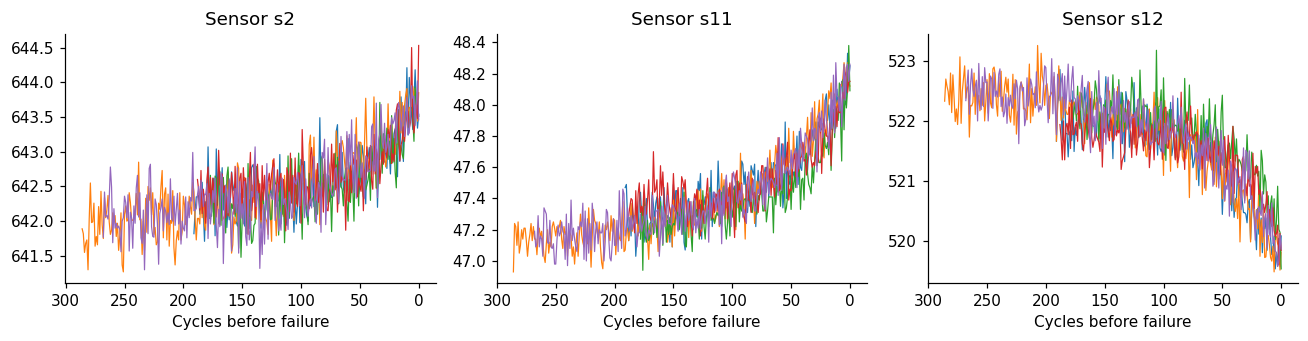

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, s in zip(axes, ["s2", "s11", "s12"]):
    for u in [1, 2, 3, 4, 5]:
        d = tr1[tr1.unit == u]
        ax.plot(d.RUL, d[s], lw=0.8)
    ax.set_title(f"Sensor {s}"); ax.set_xlabel("Cycles before failure"); ax.invert_xaxis()
plt.tight_layout(); plt.savefig(f"{FIG}/01_sensor_degradation.png"); plt.show()

Sensors drift steadily as an engine approaches failure, which is the signal a predictive model can use.

## 2. Target and features
**Target:** `fail_30` = 1 if the engine will fail within the next 30 cycles. This is the early-warning window.

**Features** (per engine, using only past cycles): normalised sensor value, 10-cycle rolling mean, 10-cycle change, and the cycle count.

In [4]:
H = 30
def fit_norm(df, regime):
    g = df[sensors].groupby(regime)
    return g.mean(), g.std().replace(0, 1)

def make_features(df, mu, sd, regime):
    z = (df[sensors].values - mu.loc[regime].values) / sd.loc[regime].values
    Z = pd.DataFrame(z, columns=sensors, index=df.index)
    Z["unit"] = df.unit.values
    g = Z.groupby("unit")[sensors]
    cur = Z[sensors].add_suffix("_now")
    m10 = g.rolling(10, min_periods=1).mean().reset_index(level=0, drop=True).reindex(Z.index).add_suffix("_m10")
    d10 = (Z[sensors] - g.shift(10)).fillna(0).add_suffix("_d10")
    out = pd.concat([cur, m10, d10], axis=1)
    out["cycle"] = df.cycle.values
    return out

reg1_tr = np.zeros(len(tr1), dtype=int); reg1_te = np.zeros(len(te1), dtype=int)
mu1, sd1 = fit_norm(tr1, reg1_tr)
X1 = make_features(tr1, mu1, sd1, reg1_tr)
y1 = (tr1.RUL <= H).astype(int)
print("Feature matrix:", X1.shape, "| positive rate:", f"{y1.mean():.1%}")

Feature matrix: (20631, 43) | positive rate: 15.0%


## 3. Engine-wise split (no engine appears in two sets)
Train 70 engines, validation 15 (to pick the alert threshold), test 15. Later we also check the official NASA test set.

In [5]:
rng = np.random.RandomState(0)
units = rng.permutation(tr1.unit.unique())
u_tr, u_va, u_te = units[:70], units[70:85], units[85:]
m_tr, m_va, m_te = tr1.unit.isin(u_tr).values, tr1.unit.isin(u_va).values, tr1.unit.isin(u_te).values
Xtr, ytr, Xva, yva, Xte, yte = X1[m_tr], y1[m_tr], X1[m_va], y1[m_va], X1[m_te], y1[m_te]
print(f"train {len(Xtr)} rows (alerts {ytr.sum()}) | val {len(Xva)} ({yva.sum()}) | test {len(Xte)} ({yte.sum()})")

train 14558 rows (alerts 2170) | val 3035 (465) | test 3038 (465)


## 4. Models and baselines
- **Age rule (scheduled maintenance):** alert purely by cycle count. This mimics fixed-schedule maintenance.
- **Simple sensor rule:** one sensor (the one most correlated with failure on the training engines), smoothed over 10 cycles.
- **Logistic Regression, Random Forest, XGBoost** with class weighting, since alerts are rare.

In [6]:
corr = {c: abs(np.corrcoef(Xtr[c], ytr)[0, 1]) for c in Xtr.columns if c.endswith("_m10")}
rule_col = max(corr, key=corr.get)
rule_sign = np.sign(np.corrcoef(Xtr[rule_col], ytr)[0, 1])
print("Simple rule uses:", rule_col, "(sign", int(rule_sign), ")")

pos_w = (ytr == 0).sum() / (ytr == 1).sum()
def new_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)),
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=0),
        "XGBoost": XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.05, subsample=0.8,
                                 colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric="aucpr",
                                 random_state=0, n_jobs=-1),
    }
models = new_models()
for m in models.values():
    m.fit(Xtr, ytr)

def score(name, X):
    if name == "Age rule (cycle count)": return X["cycle"].values
    if name == "Simple sensor rule": return rule_sign * X[rule_col].values
    return models[name].predict_proba(X)[:, 1]

names = ["Age rule (cycle count)", "Simple sensor rule"] + list(models)
rows = [["Random guess (alert rate)", yte.mean(), 0.5]]
for n in names:
    p = score(n, Xte)
    rows.append([n, average_precision_score(yte, p), roc_auc_score(yte, p)])
res = pd.DataFrame(rows, columns=["Model", "PR-AUC", "ROC-AUC"]).set_index("Model").round(3)
res

Simple rule uses: s15_m10 (sign 1 )


,PR-AUC,ROC-AUC
Model,,
Random guess (alert rate),0.153,0.500
Age rule (cycle count),0.708,0.937
Simple sensor rule,0.875,0.970
Logistic Regression,0.946,0.987
Random Forest,0.938,0.986
XGBoost,0.944,0.987


Only 15 test engines is a small sample, so we also run **5-fold cross-validation by engine** over all 100 engines for a more reliable comparison.

In [7]:
gkf = GroupKFold(n_splits=5)
cv = {n: [] for n in names}
for a, b in gkf.split(X1, y1, groups=tr1.unit):
    Xa, ya, Xb, yb = X1.iloc[a], y1.iloc[a], X1.iloc[b], y1.iloc[b]
    pw = (ya == 0).sum() / (ya == 1).sum()
    ms = new_models(); ms["XGBoost"].set_params(scale_pos_weight=pw)
    for m in ms.values(): m.fit(Xa, ya)
    for n in names:
        if n == "Age rule (cycle count)": p = Xb["cycle"].values
        elif n == "Simple sensor rule": p = rule_sign * Xb[rule_col].values
        else: p = ms[n].predict_proba(Xb)[:, 1]
        cv[n].append(average_precision_score(yb, p))
cvt = pd.DataFrame({n: [np.mean(v), np.std(v)] for n, v in cv.items()}, index=["PR-AUC mean", "PR-AUC std"]).T.round(3)
cvt

,PR-AUC mean,PR-AUC std
Age rule (cycle count),0.526,0.029
Simple sensor rule,0.912,0.007
Logistic Regression,0.957,0.008
Random Forest,0.952,0.009
XGBoost,0.956,0.009


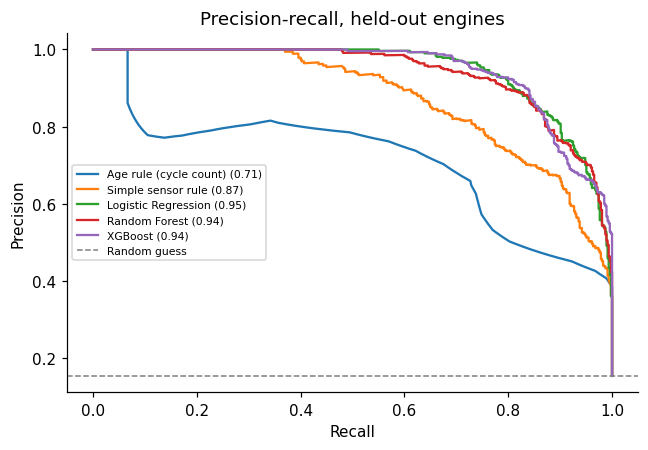

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for n in names:
    p, r, _ = precision_recall_curve(yte, score(n, Xte))
    ax.plot(r, p, label=f"{n} ({average_precision_score(yte, score(n, Xte)):.2f})")
ax.axhline(yte.mean(), ls="--", color="grey", lw=1, label="Random guess")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall, held-out engines")
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{FIG}/02_precision_recall.png"); plt.show()

## 5. Alerts and the cost of false alarms
The alert threshold is chosen on the **validation engines** (best F2, which favours catching failures). Then we count alerts on the test engines.

**Assumption (adjustable):** a missed warning costs 10 units, a false alarm costs 1 unit.

In [9]:
def pick_threshold(name):
    p, r, t = precision_recall_curve(yva, score(name, Xva))
    f2 = 5 * p[:-1] * r[:-1] / (4 * p[:-1] + r[:-1] + 1e-9)
    return t[np.nanargmax(f2)]

COST_FN, COST_FP = 10, 1
thr = {n: pick_threshold(n) for n in names}
out = []
for n in names:
    pred = (score(n, Xte) >= thr[n]).astype(int)
    tp = int(((pred == 1) & (yte == 1)).sum()); fp = int(((pred == 1) & (yte == 0)).sum()); fn = int(((pred == 0) & (yte == 1)).sum())
    out.append([n, round(tp / max(tp + fp, 1), 2), round(tp / max(tp + fn, 1), 2), fp, fn, COST_FN * fn + COST_FP * fp])
out.append(["No model (never alert)", np.nan, 0.0, 0, int(yte.sum()), COST_FN * int(yte.sum())])
alert = pd.DataFrame(out, columns=["Model", "Precision", "Recall", "False alarms", "Missed", "Cost"]).set_index("Model")
alert

,Precision,Recall,False alarms,Missed,Cost
Model,,,,,
Age rule (cycle count),0.57,0.75,260,117,1430
Simple sensor rule,0.71,0.83,159,79,949
Logistic Regression,0.75,0.93,147,34,487
Random Forest,0.63,0.97,270,13,400
XGBoost,0.64,0.97,257,14,397
No model (never alert),NaN,0.00,0,465,4650


**Engine view:** for each held-out engine, how many cycles before failure does the XGBoost model first raise an alert (3 cycles in a row above threshold)?

In [10]:
p_te = score("XGBoost", Xte)
d = tr1[m_te].assign(p=p_te)
lead = []
for u, g in d.groupby("unit"):
    flag = (g.p >= thr["XGBoost"]).rolling(3).sum().fillna(0) >= 3
    lead.append(int(g.RUL[flag].iloc[0]) if flag.any() else np.nan)
lead = pd.Series(lead, index=sorted(d.unit.unique()), name="RUL at first alert")
print("Cycles before failure at first alert (per engine):", lead.dropna().astype(int).tolist())
print(f"Median lead time: {lead.median():.0f} cycles | engines never alerted: {int(lead.isna().sum())} of {len(lead)}")

Cycles before failure at first alert (per engine): [26, 38, 79, 35, 26, 32, 27, 22, 82, 47, 43, 113, 41, 31, 31]
Median lead time: 35 cycles | engines never alerted: 0 of 15


**Official NASA test set check:** the last recorded cycle of each of the 100 test engines, with the true RUL from NASA's answer file.

In [11]:
X1_te = make_features(te1, mu1, sd1, reg1_te)
last_idx = te1.groupby("unit").cycle.idxmax()
Xo, yo = X1_te.loc[last_idx], (te1.loc[last_idx, "RUL"] <= H).astype(int)
rows = [["Random guess (alert rate)", yo.mean(), 0.5, np.nan, np.nan]]
for n in names:
    p = score(n, Xo); pred = (p >= thr[n]).astype(int)
    tp = int(((pred == 1) & (yo == 1)).sum())
    rows.append([n, average_precision_score(yo, p), roc_auc_score(yo, p), tp / max(pred.sum(), 1), tp / yo.sum()])
pd.DataFrame(rows, columns=["Model", "PR-AUC", "ROC-AUC", "Precision", "Recall"]).set_index("Model").round(2)

,PR-AUC,ROC-AUC,Precision,Recall
Model,,,,
Random guess (alert rate),0.25,0.50,NaN,NaN
Age rule (cycle count),0.51,0.80,0.50,0.52
Simple sensor rule,0.89,0.96,0.82,0.72
Logistic Regression,0.95,0.98,0.88,0.84
Random Forest,0.95,0.98,0.77,0.96
XGBoost,0.94,0.98,0.79,0.88


## 6. Explainability with SHAP (XGBoost)

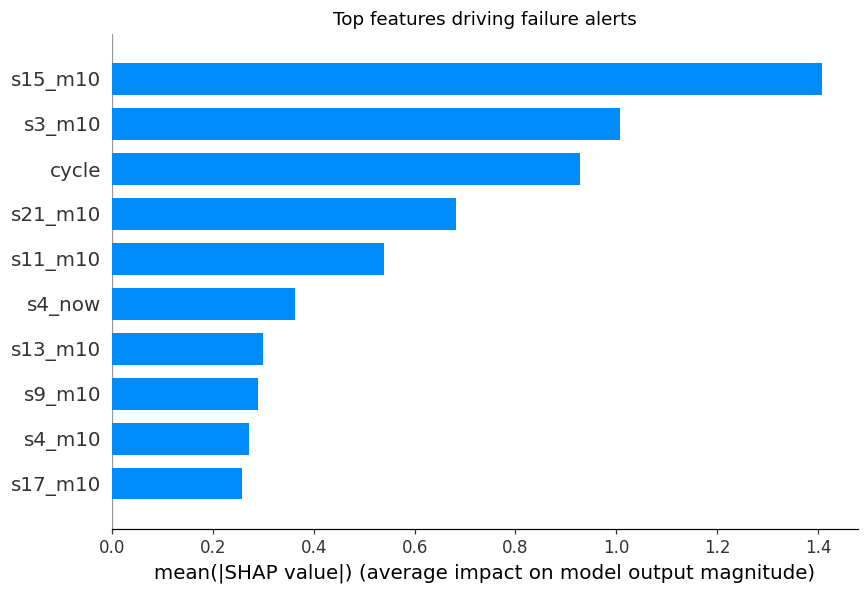

In [12]:
explainer = shap.TreeExplainer(models["XGBoost"])
Xs = Xte.sample(1500, random_state=0)
sv = explainer.shap_values(Xs)
plt.figure()
shap.summary_plot(sv, Xs, plot_type="bar", max_display=10, show=False)
plt.title("Top features driving failure alerts"); plt.tight_layout()
plt.savefig(f"{FIG}/03_shap_importance.png", bbox_inches="tight"); plt.show()

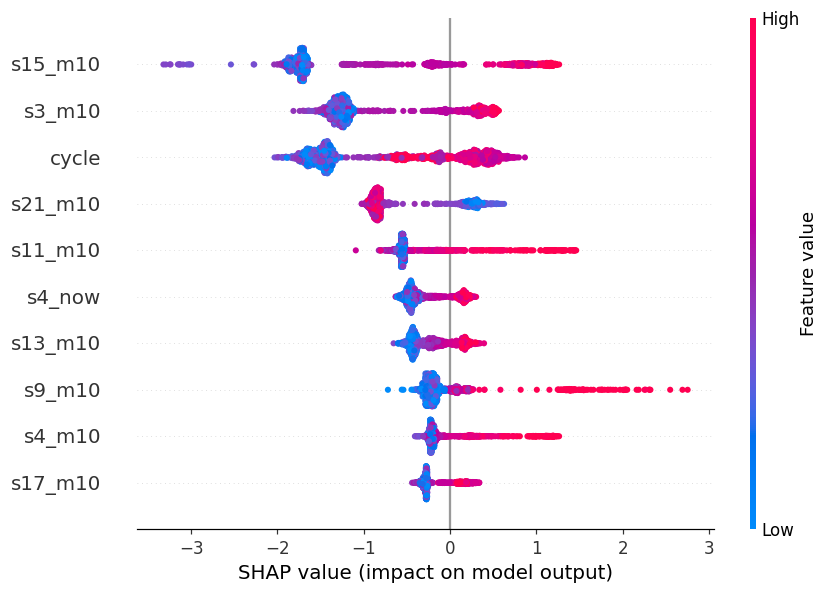

In [13]:
plt.figure()
shap.summary_plot(sv, Xs, max_display=10, show=False)
plt.tight_layout(); plt.savefig(f"{FIG}/04_shap_beeswarm.png", bbox_inches="tight"); plt.show()

**One alert explained:** the highest-risk cycle among held-out engines.

In [14]:
i = int(np.argmax(p_te)); row = Xte.iloc[[i]]
sv1 = pd.Series(explainer.shap_values(row)[0], index=Xte.columns)
top = sv1.reindex(sv1.abs().sort_values(ascending=False).index).head(5)
print(f"Engine {int(tr1[m_te].unit.iloc[i])}, cycle {int(tr1[m_te].cycle.iloc[i])} | risk {p_te[i]:.2f} | true cycles to failure: {int(tr1[m_te].RUL.iloc[i])}")
pd.DataFrame({"value (normalised)": row[top.index].iloc[0].round(2), "pushes risk": top.round(2)})

Engine 13, cycle 162 | risk 1.00 | true cycles to failure: 1


,value (normalised),pushes risk
s9_m10,3.26,1.36
s15_m10,1.85,1.12
s4_m10,1.88,0.96
s14_now,3.92,0.89
s11_m10,1.89,0.81


## 7. Drift awareness: new operating conditions (FD002)
FD001 has one operating condition. **FD002 has six**, so sensor values shift with the flight regime even for a healthy engine. This is a realistic drift scenario: the model was trained in one setting and is deployed in another.

**Step 1: detect drift.** Compare each sensor's distribution in FD001 and FD002 with the Kolmogorov-Smirnov statistic (0 = identical, 1 = completely different).

In [15]:
tr2 = load("train_FD002")
tr2["RUL"] = tr2.groupby("unit").cycle.transform("max") - tr2.cycle
y2 = (tr2.RUL <= H).astype(int)
ops = StandardScaler().fit_transform(tr2[["op1", "op2", "op3"]])
km = KMeans(n_clusters=6, n_init=10, random_state=0).fit(ops)
reg2 = km.labels_
print("FD002 engines:", tr2.unit.nunique(), "| rows:", len(tr2), "| operating regimes found:", np.bincount(reg2).tolist())

ks_raw = pd.Series({s: ks_2samp(tr1[s], tr2[s]).statistic for s in sensors}).sort_values(ascending=False)
print(f"Mean KS (raw sensors, FD001 vs FD002): {ks_raw.mean():.2f}")
ks_raw.head(8).round(2).to_frame("KS statistic")

FD002 engines: 260 | rows: 53759 | operating regimes found: [13458, 8044, 8002, 8122, 8096, 8037]
Mean KS (raw sensors, FD001 vs FD002): 0.80


,KS statistic
s3,0.85
s9,0.85
s2,0.85
s4,0.85
s7,0.85
s8,0.85
s11,0.85
s12,0.85


**Step 2: measure the damage.** Apply the FD001-trained XGBoost model to FD002 engines it has never seen.
- **Naive:** normalise with FD001 statistics (what a deployed model would do by default).
- **Drift-aware:** detect the operating regime and normalise each regime separately.

In [16]:
reg0 = np.zeros(len(tr2), dtype=int)
X2_naive = make_features(tr2, mu1, sd1, reg0)
mu2, sd2 = fit_norm(tr2, reg2)
X2_aware = make_features(tr2, mu2, sd2, reg2)

ks_norm = pd.Series({s: ks_2samp(X1[f"{s}_now"], X2_aware[f"{s}_now"]).statistic for s in sensors})
print(f"Mean KS after regime normalisation: {ks_norm.mean():.2f} (was {ks_raw.mean():.2f})")

def evaluate(Xe, ye, name="XGBoost"):
    p = models[name].predict_proba(Xe)[:, 1]; pred = (p >= thr[name]).astype(int)
    tp = int(((pred == 1) & (ye == 1)).sum())
    return [average_precision_score(ye, p), roc_auc_score(ye, p), tp / max(pred.sum(), 1), tp / ye.sum()]

drift_tbl = pd.DataFrame(
    [["FD001 held-out engines (no drift)"] + evaluate(Xte, yte),
     ["FD002, naive (FD001 normalisation)"] + evaluate(X2_naive, y2),
     ["FD002, drift-aware (per-regime normalisation)"] + evaluate(X2_aware, y2)],
    columns=["Scenario", "PR-AUC", "ROC-AUC", "Precision", "Recall"]).set_index("Scenario").round(2)
drift_tbl

Mean KS after regime normalisation: 0.04 (was 0.80)


,PR-AUC,ROC-AUC,Precision,Recall
Scenario,,,,
FD001 held-out engines (no drift),0.94,0.99,0.64,0.97
"FD002, naive (FD001 normalisation)",0.30,0.69,0.61,0.04
"FD002, drift-aware (per-regime normalisation)",0.94,0.99,0.73,0.94


**Step 3: retrain on the new conditions.** Train a fresh model on 70% of FD002 engines (with regime normalisation) and compare it with the transferred FD001 model on the same held-out FD002 engines.

In [17]:
u2 = np.random.RandomState(1).permutation(tr2.unit.unique())
a2, b2 = tr2.unit.isin(u2[:182]).values, tr2.unit.isin(u2[182:]).values
retrained = XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=(y2[a2] == 0).sum() / (y2[a2] == 1).sum(), eval_metric="aucpr",
                          random_state=0, n_jobs=-1).fit(X2_aware[a2], y2[a2])
cmp_rows = []
for label, mdl, Xe in [("FD001 model, naive", models["XGBoost"], X2_naive[b2]),
                       ("FD001 model, drift-aware features", models["XGBoost"], X2_aware[b2]),
                       ("Retrained on FD002, drift-aware features", retrained, X2_aware[b2])]:
    p = mdl.predict_proba(Xe)[:, 1]
    cmp_rows.append([label, average_precision_score(y2[b2], p), roc_auc_score(y2[b2], p)])
cmp = pd.DataFrame(cmp_rows, columns=["Approach", "PR-AUC", "ROC-AUC"]).set_index("Approach").round(2)
print(f"Held-out FD002 engines: {len(u2) - 182} | alert rate {y2[b2].mean():.1%}")
cmp

Held-out FD002 engines: 78 | alert rate 14.8%


,PR-AUC,ROC-AUC
Approach,,
"FD001 model, naive",0.28,0.68
"FD001 model, drift-aware features",0.94,0.99
"Retrained on FD002, drift-aware features",0.96,0.99


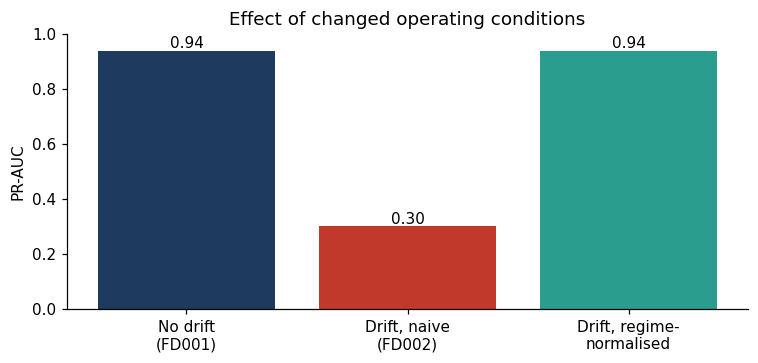

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.4))
vals = [drift_tbl.iloc[0, 0], drift_tbl.iloc[1, 0], drift_tbl.iloc[2, 0]]
ax.bar(["No drift\n(FD001)", "Drift, naive\n(FD002)", "Drift, regime-\nnormalised"], vals, color=["#1F3A5F", "#C0392B", "#2A9D8F"])
for i, v in enumerate(vals): ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylabel("PR-AUC"); ax.set_ylim(0, 1); ax.set_title("Effect of changed operating conditions")
plt.tight_layout(); plt.savefig(f"{FIG}/05_drift_effect.png"); plt.show()

## 8. Findings (from our run)
1. **ML beats the baselines.** On held-out engines, XGBoost reached PR-AUC 0.94 and Logistic Regression 0.95, versus 0.88 for the best single-sensor rule, 0.71 for age-based maintenance and 0.15 for a random guess. In 5-fold cross-validation by engine the gap holds (about 0.95 vs 0.91 vs 0.53). Logistic Regression is as good as XGBoost, so a simple model is enough here.
2. **Alerts.** At the validation-chosen threshold, XGBoost caught 97% of the failing cycles (14 missed of 465) with 257 false alarms. The single-sensor rule missed 79 and the age rule 117. Under our assumed 10:1 miss-to-false-alarm cost, XGBoost cost 397 against 1,430 for age-based maintenance and 4,650 for no model. The median warning came 35 cycles before failure, and no held-out engine went unwarned.
3. **Explainability.** SHAP ranks smoothed sensor 15, smoothed sensor 3, engine age (cycle count), smoothed sensor 21 and smoothed sensor 11 as the strongest drivers of alerts.
4. **Drift is large and fixable.** FD002 has six operating conditions, so raw sensor distributions differ sharply from FD001 (mean KS 0.80). The FD001 model with default normalisation fell to PR-AUC 0.30 and recall 0.04, so it almost never alerted. Detecting the operating regime and normalising per regime cut the KS to 0.04 and restored PR-AUC to 0.94 with no retraining. Retraining on FD002 gave 0.96.

**Limitations:** C-MAPSS is simulated turbofan data, not smart grid equipment; the 30-cycle window and the 10:1 cost ratio are assumptions; the split uses only 100 engines (so we added cross-validation); the official NASA test check uses just one cycle per engine; and no LSTM was trained here.